In [1]:
# pip install ipywidgets

# after installing this module -> RESTART YOUR KERNEL in this notebook

# Feature Transformation / Exploration

###  <i> Using t-SNE </i>

####  [Video that explains t-SNE](https://www.youtube.com/watch?v=Bl85EfTiGj0&t=461s) 

<br>
<br>

<i>

### Summary

t-SNE is a way to get a visual feel for how complex the relationships between your features are. And just saying that alone is a lot to unpack. Normally this is impossible, because in order to visualize the relationships, you often see it in more than 3 dimensions (10 features? 10 dimensions).

<strong style='color:orange ; background-color:black;'> t-SNE is a data transformation that remaps the features in a 2D space. </strong> 

<br>
<br>

<i> An example visual using t-SNE

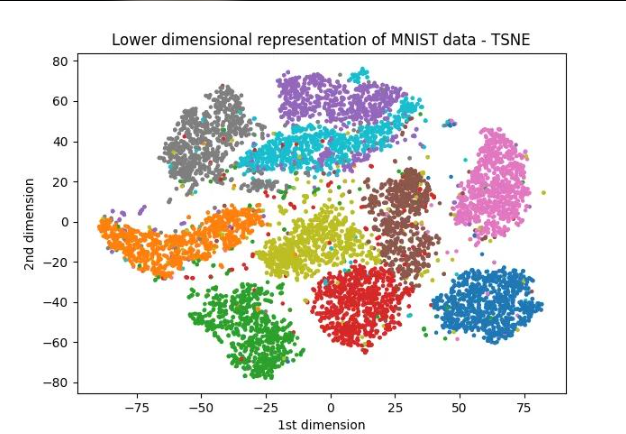

<br>
<br>


### How it works 

<i> A representation of how t-SNE works. (Oversimplified) t-SNE takes feature data and calculates how similar each point is to one another (could be many dimensions). It converts these distances into probabilities representing how likely points are to be neighbors! Then it maps the data into 2D via multiple iterations of arranging points, `max_iter`. In the end, you get a visualization where the similar points in feature space are close to each other and show some local patterns.

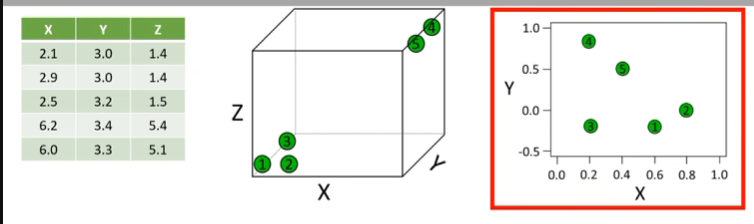



<br>
<br>

### Caveats

There are some important caveats with t-SNE -- And the most important caveat is that <strong style='color:orange ; background-color:black;'> these visualizations are oversimplifications of the real relationships between these features </strong>. You're going to have to experiment a bit and the visualizations can ONLY give you CLUES AND GLIMPSES of the depth and complexity of your data.


<strong style='color:orange; background-color:black'> Therefore, take your findings using t-SNE with a scientific grain of salt.</strong>


<strong> [Article that explains how to use t-sne + more caveats](https://medium.com/data-science/t-sne-clearly-explained-d84c537f53a) </strong>

<br>
<br>

</i>

### How can t-SNE help you? 

|It can help you understand:|
|---|
|<strong style='color:orange ; background-color:black;'> Which ML model to use! t-SNE is used a lot for getting a baseline to figure out which model you want to utilize first. </strong> |
|<strong>It can tell you the complexity of the relationships between your features. If they're complex and non-linear, you'll know to use ml models that can handle non-linearity + complexity like `RandomForest`, `RBF`, `GradientBoost` or neural networks|
|<strong>Whether or not outliers exist, overlap exists, and if there are meaningful clusters/neighborhoods in your data. This lets you recognize whether feature engineering has room to add more clarity to relationships and improve your model.|
|<strong>t-SNE can evaluate your data transformations after using PCA, KPCA, Scalers. This answers the question: do these transformations still preserve the neighborhoods and relationships of your dataset even though you condensed the amount of features?|

<br>
<br>

Now, let's take a look at the function and some examples!


---

### t-SNE slider function

<i> 

`Tensorflow`, `scikit-learn`, and `Yellowbrick` all have t-SNE methods for us to use -- But they're not terribly intuitive. This is because <strong style='color:red'> in order to use t-SNE effectively, you must experiment with both PERPLEXITY and the MAXIMUM ITERATIONS. It is NOT INTUITIVE to balance two parameters like this.</strong>

<br>

Therefore, because I'm not satisfied with the existing options in all of the libraries, I'm creating a <u> better, easy-to-use method using a perplexity slider.</u>

In [2]:
'''
REQUIREMENTS
All columns MUST be numeric. 
`max_iter` minimum is 250.

FUNCTION:
This function splits the target with it's features, scales the features (standard scaler), and creates
a t-SNE plot with a slider using the given max iterations. 

PARAMETERS
df            : Pandas dataframe
target_column : string (of pandas series/column)
max_iter      : Number of adjustments to initial arrangement of points.

HOW TO READ t-SNE
* Are the clusters clearly seperated? (Then start with a simple ML model)
* Are the clusters overlapping/noisy? (Understand why overlap exists/Clean data/Complex model)
* Are there any isolated points? (Suggests better outlier mitigation)
* Are there any non linear patterns? (Then try nonlinear models, RandomForest, Gradient Boost, ANN)
'''
def plot_tsne(df, target_column, max_iter=1000):

    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd
    import ipywidgets as widgets
    from IPython.display import display
    from sklearn.manifold import TSNE
    from sklearn.preprocessing import StandardScaler

    # Set the theme to dark to avoid eye-burning sensations.
    sns.set_theme(style="dark")

    # Separate features and target
    X = df.drop(target_column, axis=1)
    y = df[target_column]

    # Scale the features
    X_scaled = StandardScaler().fit_transform(X)

    # Function called when the slider changes
    def update_tsne(perplexity):

        tsne = TSNE(
            n_components=2,
            perplexity=perplexity,
            max_iter=max_iter,
            init="pca",
            random_state=42,
            learning_rate="auto"
        )

        embedded = tsne.fit_transform(X_scaled)

        # Create DataFrame for Seaborn
        tsne_df = pd.DataFrame({
            "TSNE_1": embedded[:, 0],
            "TSNE_2": embedded[:, 1],
            "target": y.to_numpy()
        })

        # IF YOU ARE NOT SATISFIED WITH THE SIZE
        # CHANGE IT HERE (X, Y)
        plt.figure(figsize=(13, 7))

        # Now, we make the scatterplot -- Using T-SNE dimensions to plot!
        sns.scatterplot(
            data=tsne_df,
            x="TSNE_1",
            y="TSNE_2",
            hue="target",
            palette="viridis"
        )

        plt.title(f" t-SNE, Iterations: {max_iter}")
        plt.show()

    # Finally, we create a slider to manage the perplexity.
    slider = widgets.IntSlider(
        value=30,
        min=5,
        max=min(50, len(df) - 1),
        step=1,
        description="Perplexity:",
        continuous_update=False
    )

    display(widgets.interactive(update_tsne, perplexity=slider))

<i> Now we have a neat function with a slider. Let's use it!

--- 

### Using t-SNE Example 1:

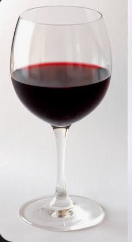


####  <i>Scikit-learn wine dataset



<i> Let's first start with a really simple dataset to familiarize you with how to use our t-SNE function. It's similar to Tuomas' wine dataset, but it's a bit more simplified.

In [3]:
from sklearn.datasets import load_wine
import pandas as pd

# Load the wine dataset
data = load_wine()

# Turn it into a pandas dataframe and concat the target (for some reason it's separate.) 
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target
df


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


### How to use `plot_sne`

<i> 

To use `plot_tsne`, you insert into the function:  

* a pandas dataframe

* the target column

* and a number of max iterations. </u>

<br>
<br>

<b> <u>  Now, you may be asking: </u> </b> 

How do I know how which value to pass into `max_iter`?


<br>
<br>



<strong style='color:red'>That's the NEAT PART. YOU DONT.  </strong>
You experiment (min 250, 500, 1000, 2000
are a decent baseline.) 

<br>
<br>

The goal is to find the point where t-SNE has converged and running more iterations no longer meaningfully improves the embedding.

<strong style='color:purple ; background-color:black;'>IN OTHER WORDS: When it stabilizes and doesn't move much anymore -- That's when you have the right `max_iter`. </strong>


<br>

 
<strong style='color:red'> If you're not sure, higher is better than lower.</strong>

In [ ]:
plot_tsne(df, "target" , max_iter=1000)

# Now, you move around the perplexity slider. Just like `max_iter`, you have found the sweet spot when 
# it remains mostly consistent in a specific range of values. 

# In this case, we see stability in Perplexity 28-36

# If you're seeing a rotation, that's normal! (though dizzifying!)

interactive(children=(IntSlider(value=30, continuous_update=False, description='Perplexity:', max=50, min=5), …

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>What is t-SNE telling us?</h3>


#### <strong style='color:orange'> Are the clusters distinguishable? </strong>

Yep! The features are very distinguishable. Try a simpler model model first.

#### <strong style='color:orange'>  Are there any isolated cases? </strong>

Yep, a few outliers. Not really enough to cause an issues (depending on use case)

#### <strong style='color:orange'>  Is there any overlap?</strong>

Yeah, actually there's a very little bit of overlap between the features! You could find those overlapping features and see if getting rid of them improves the model. Trivial? Difficult to say, depends on use case.

#### <strong style='color:orange'>  Are the relationships non-linear?</strong>

It appears to be mostly linear.

If it showed really sharp stuttering and noise, or maybe shapes, circles, especially overlapping shapes -- You're in trouble and may need to use KPCA or manage that noise and re-use t-SNE.
You would also consider a non-linear model like `RandomForest`. 


### <strong style='color:orange'>  Verdict</strong>

* Check out the outliers and maybe fix.
* Check out the overlap and maybe fix.
* Try an computation-light model first (`LinearRegression`, `Decision Tree`, `Linear SVM`)
* Then try a computation-heavier model (`RandomForest`, `GradientBoost`)
* Compare differences!
</div>

--- 



### Using t-SNE Example 2:


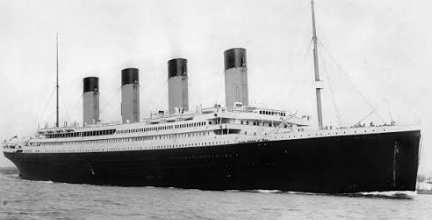

####  <i>Titanic Dataset

<i> Now, we're going to be showcasing a more complex dataset to show you how it can help you. This is REALLY where t-SNE shines. From complex data, you'll be able to determine the groups and neighborhoods where ML models can determine the classes.


#### Loading and Cleaning

In [5]:
import seaborn as sns 

# Load the Titanic dataset
df = sns.load_dataset("titanic")
df

# Median Imputation
df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

# Mode imputation
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])

# Set the unknown deck value as unknown, since we can't accurately compute this.
df["deck"] = df["deck"].cat.add_categories(["Unknown"]).fillna("Unknown")

# Remove redundant columns and target leakages.
df = df.drop(columns=[
    "alive",       # duplicates survived
    "class",       # duplicates pclass
    "embark_town", # duplicates embarked
    "who",         # derived from age and sex
    "adult_male",  # derived from age and sex
    "alone"        # derived from family counts
])

# Encoding
# sex -- binary but use ordinal mapping. 
category_mapper = {'male':0,'female':1}
df['sex'] = df['sex'].map(category_mapper)

# embarked and deck -- nominal
from sklearn.preprocessing import OneHotEncoder
categorical_columns = ["embarked","deck"]

for column in categorical_columns:
    encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
    one_hot_encoded = encoder.fit_transform(df[[column]]).astype(int)
    df = pd.concat([df.drop(columns=[column]), one_hot_encoded], axis=1)

df

,survived,pclass,sex,age,sibsp,parch,fare,embarked_C,embarked_Q,embarked_S,deck_A,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G,deck_Unknown
0,0,3,0,22.0,1,0,7.2500,0,0,1,0,0,0,0,0,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0,0,0,1,0,0,0,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1,0,0,0,0,0,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1,0,0,1,0,0,0,0,0
4,0,3,0,35.0,0,0,8.0500,0,0,1,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,0,27.0,0,0,13.0000,0,0,1,0,0,0,0,0,0,0,1
887,1,1,1,19.0,0,0,30.0000,0,0,1,0,1,0,0,0,0,0,0
888,0,3,1,28.0,1,2,23.4500,0,0,1,0,0,0,0,0,0,0,1
889,1,1,0,26.0,0,0,30.0000,1,0,0,0,0,1,0,0,0,0,0


### t-SNE

In [6]:
plot_tsne(df, "survived", max_iter=1200)

interactive(children=(IntSlider(value=30, continuous_update=False, description='Perplexity:', max=50, min=5), …

In [ ]:
# low perplexity => local clusters
# high perplexity => broad clusters

# t-SNE can be particularly useful for visually investigating overlap, similarity, and potential contradictions between data groupings.

# What you observe                        What it might suggest
# Overlap at all perplexities             Potentially robust similarity
# Overlap only at low perplexity          Local similarities or small subgroups
# Overlap only at high perplexity         Broader neighborhood relationships
# Separation at low but overlap at high   Locally distinct but globally related structures

# Observation                                         Possible interpretation
# Compact clusters                                    Similar learned representations
# Overlapping clusters                                Similarity between representations
# Clearly separated clusters                          Potentially distinct representation patterns
# Clusters changing dramatically with perplexity      Structure may be sensitive to neighborhood scale

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>What is t-SNE telling us?</h3>


#### <strong style='color:orange'> Are the clusters distinguishable? </strong>

Yeah, definitely distinguishable! Notice how there are clear groups and neighborhoods here that probably associate between `sex`, `age`, `fare`. These groups are clearly occupying their own regions and all have distinguishable differences in the dataset.

The majority of the passengers that were men and in a lower `fare` class likely represents that curved line.

Overall, good sign. This is manageable for ML models.

#### <strong style='color:orange'>  Are there any isolated cases? </strong>

A few stragglers yes, but not a lot. For optimization, it's worth looking into.

#### <strong style='color:orange'>  Is there any overlap?</strong>

Yeah, lots of overlap. 

This suggests that we may need to look into the data a bit more or/and that we have to select a robust ML model. 

Consider `GradientBoost`, `XGBoost` or even an ensemble method if computation power isn't an issue. If computation is an issue, perhaps `RandomForest` or `RBF`. Overall, this is the pain-point for the model.

#### <strong style='color:orange'>  Are the relationships non-linear?</strong>


### <strong style='color:orange'>  Verdict</strong>


* Distinguishable neighborhoods
* Small number of outliers. Worth checking and investigating, but otherwise trivial.
* Consider interaction features or feature transformations to unravel the overlap.
* Try a computation-heavier model (`RandomForest`, `GradientBoost`, `XGBoost`, `RBF`, even ensemble methods)
* A reasonably challenging problem, definitely not impossible.
</div>


<i>

* `t-SNE` is kind of strange to use at first, but it's used frequently in EDA. This is considered a feature engineering (feature transformation) tool because we can visualize our features and their relationships.

